In [2]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 4.6 MB/s  0:00:00 eta 0:00:01


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from xgboost import XGBClassifier


In [4]:
# 1. Load Iris dataset
data = pd.read_csv("Iris.csv")

print("First 5 rows:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)



First 5 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Shape:
(150, 6)


In [5]:
# 2. Select features and target
X = data.iloc[:, 1:5]      # SepalLength, SepalWidth, PetalLength, PetalWidth
y = data["Species"]


In [6]:
# 3. Convert target classes into numbers
# Setosa = 0, Versicolor = 1, Virginica = 2
y = y.map({
    "Iris-setosa": 0,
    "Iris-versicolor": 1,
    "Iris-virginica": 2
})


In [7]:
# 4. Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [8]:
# 5. Create models

# AdaBoost
ada_model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

# Gradient Tree Boosting
gbm_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss"
)


In [9]:
# 6. Store models
models = {
    "AdaBoost": ada_model,
    "Gradient Boosting": gbm_model,
    "XGBoost": xgb_model
}

In [10]:
# 7. Train and evaluate models
results = []

for name, model in models.items():

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluation
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted")
    recall = recall_score(y_test, y_pred, average="weighted")
    f1 = f1_score(y_test, y_pred, average="weighted")

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])


In [11]:
# 8. Create comparison table
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

print("\nModel Performance Comparison:")
print(results_df)



Model Performance Comparison:
               Model  Accuracy  Precision    Recall  F1-Score
0           AdaBoost  0.933333   0.933333  0.933333  0.933333
1  Gradient Boosting  0.966667   0.969697  0.966667  0.966583
2            XGBoost  0.933333   0.933333  0.933333  0.933333


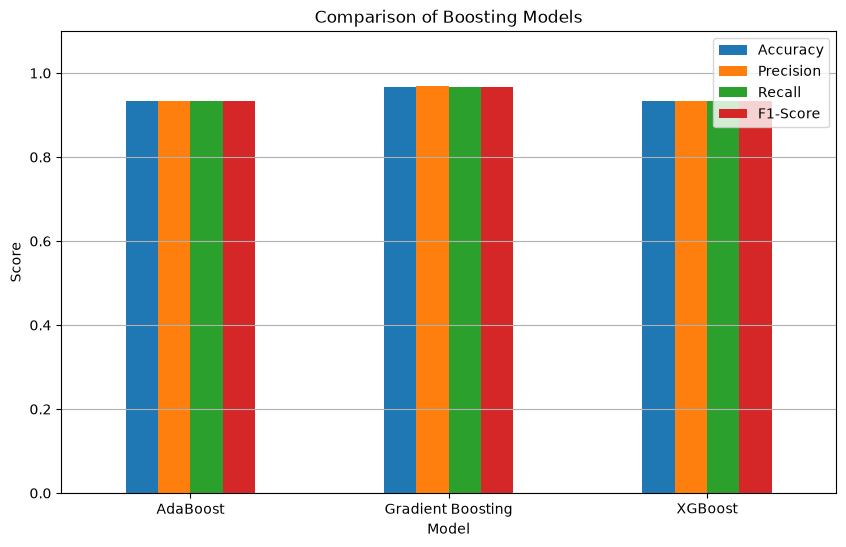

In [12]:
# 9. Plot comparison
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Boosting Models")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.show()